In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, classification_report, f1_score,
                             precision_score, recall_score, accuracy_score)

RANDOM_STATE = 42
NAVY = "#2B4570"
CARAMEL = "#C19A6B"
LIGHT_NAVY = "#9FB1CC"
GRID = "#E6E1D8"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8A8A8A",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "font.size": 10,
})
MISSING_TOKENS = ["", " ", "NA", "N/A", "null", "NaN", "?"]
df = pd.read_csv("classification_escalation.csv",
                 na_values=MISSING_TOKENS, skipinitialspace=True)
print("Shape (rows, columns):", df.shape)
print()
print(df.head())
print()
print("Missing values per column:")
print(df.isna().sum())
print()
print("Share of rows with at least one missing value: "
      f"{df.isna().any(axis=1).mean():.1%}")



Shape (rows, columns): (900, 7)

  ticket_id  complexity_score  team_experience_years  priority channel  \
0     T0000               2.0                   15.0    Medium   Email   
1     T0001               9.0                    6.0  Critical    Chat   
2     T0002              10.0                    8.0      High   Phone   
3     T0003               2.0                    1.0    Medium   Phone   
4     T0004               8.0                   14.0    Medium    Chat   

   customer_tenure_months  escalated  
0               61.818896          0  
1              110.024317          0  
2               36.311244          0  
3               85.127855          0  
4               18.225059          0  

Missing values per column:
ticket_id                  0
complexity_score          22
team_experience_years     36
priority                  13
channel                    9
customer_tenure_months    31
escalated                  0
dtype: int64

Share of rows with at least one missing val

Features used: ['complexity_score', 'team_experience_years', 'priority', 'channel', 'customer_tenure_months']

Class counts (0 = not escalated, 1 = escalated):
escalated
0    709
1    191
Name: count, dtype: int64

Baseline: escalation rate = 21.2%


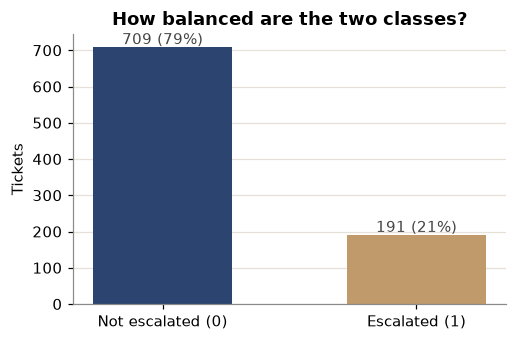

In [4]:
y = df["escalated"]
X = df.drop(columns=["ticket_id", "escalated"])

print("Features used:", list(X.columns))
print()
counts = y.value_counts().sort_index()
print("Class counts (0 = not escalated, 1 = escalated):")
print(counts)
print(f"\nBaseline: escalation rate = {y.mean():.1%}")

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.bar(["Not escalated (0)", "Escalated (1)"], counts.values,
       color=[NAVY, CARAMEL], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, f"{v} ({v/len(y):.0%})", ha="center", color="#444444")
ax.set_ylabel("Tickets")
ax.set_title("How balanced are the two classes?")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
print(f"Escalation rate in train: {y_train.mean():.3f}")
print(f"Escalation rate in test : {y_test.mean():.3f}")


Train size: 720 | Test size: 180
Escalation rate in train: 0.212
Escalation rate in test : 0.211


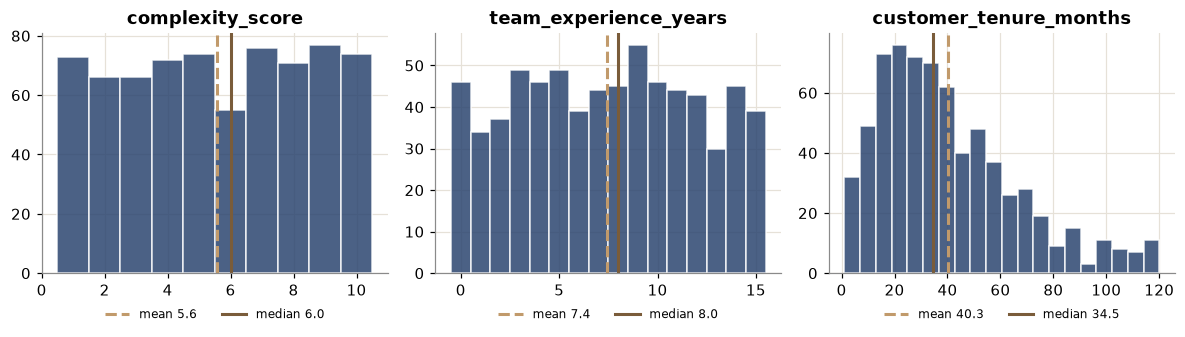

Skewness (0 = symmetric, > 0 = long right tail):
complexity_score         -0.04
team_experience_years     0.01
customer_tenure_months    0.98
dtype: float64


In [6]:
num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, num_cols):
    data = X_train[col].dropna()
    bins = np.arange(data.min() - 0.5, data.max() + 1.5) if data.nunique() <= 20 else 20
    ax.hist(data, bins=bins, color=NAVY, alpha=0.85, edgecolor="white")
    ax.axvline(data.mean(), color=CARAMEL, lw=2, ls="--", label=f"mean {data.mean():.1f}")
    ax.axvline(data.median(), color="#7A5C3A", lw=2, label=f"median {data.median():.1f}")
    ax.set_title(col)
    ax.legend(frameon=False, fontsize=8, loc="upper center",
              bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.show()

print("Skewness (0 = symmetric, > 0 = long right tail):")
print(X_train[num_cols].skew().round(2))


In [11]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

demo = preprocess.fit_transform(X_train)
print("Columns after preprocessing:", demo.shape[1])
print(list(preprocess.get_feature_names_out()))
print("Any NaN left?", bool(np.isnan(demo).any()))


Columns after preprocessing: 11
['num__complexity_score', 'num__team_experience_years', 'num__customer_tenure_months', 'cat__priority_Critical', 'cat__priority_High', 'cat__priority_Low', 'cat__priority_Medium', 'cat__channel_Chat', 'cat__channel_Email', 'cat__channel_Phone', 'cat__channel_Portal']
Any NaN left? False


In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "k-NN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

scoring = {"f1": "f1", "precision": "precision", "recall": "recall", "accuracy": "accuracy"}
rows, f1_folds = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    f1_folds[name] = res["test_f1"]
    rows.append({
        "Model": name,
        "F1 mean": res["test_f1"].mean(), "F1 std": res["test_f1"].std(),
        "Precision": res["test_precision"].mean(),
        "Recall": res["test_recall"].mean(),
        "Accuracy": res["test_accuracy"].mean(),
    })

baseline_results = pd.DataFrame(rows).set_index("Model").round(3)
print(baseline_results)
print()
for name, f in f1_folds.items():
    print(f"{name:20s} fold F1 scores: {np.round(f, 3)}")


                     F1 mean  F1 std  Precision  Recall  Accuracy
Model                                                            
Logistic Regression    0.393   0.063      0.624   0.288     0.812
k-NN                   0.361   0.050      0.562   0.268     0.800
Decision Tree          0.331   0.058      0.318   0.347     0.704

Logistic Regression  fold F1 scores: [0.391 0.326 0.364 0.372 0.511]
k-NN                 fold F1 scores: [0.367 0.326 0.426 0.286 0.4  ]
Decision Tree        fold F1 scores: [0.4   0.23  0.323 0.373 0.328]


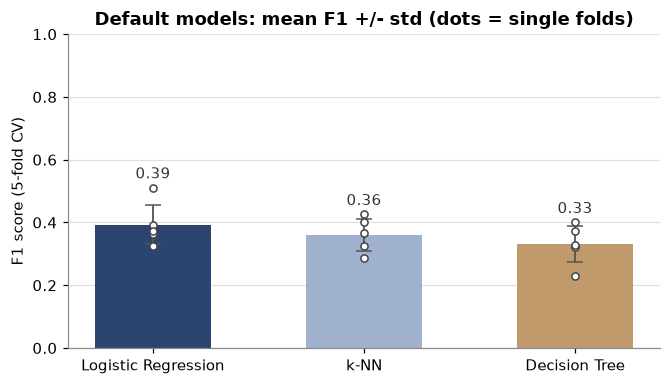

In [13]:
names = list(f1_folds)
means = [f1_folds[n].mean() for n in names]
stds = [f1_folds[n].std() for n in names]
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.bar(names, means, yerr=stds, capsize=5, color=[NAVY, LIGHT_NAVY, CARAMEL],
       width=0.55, error_kw={"ecolor": "#555555", "lw": 1.2})
for i, n in enumerate(names):
    ax.scatter([i] * 5, f1_folds[n], color="white", edgecolor="#444444", s=22, zorder=3)
    top = max(means[i] + stds[i], f1_folds[n].max())
    ax.text(i, top + 0.03, f"{means[i]:.2f}", ha="center", color="#333333")
ax.set_ylim(0, 1)
ax.set_ylabel("F1 score (5-fold CV)")
ax.set_title("Default models: mean F1 +/- std (dots = single folds)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()


In [14]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    "k-NN": {
        "model__n_neighbors": [3, 5, 7, 11, 15, 21, 31],
        "model__weights": ["uniform", "distance"],
    },
    "Decision Tree": {
        "model__max_depth": [2, 3, 4, 5, 6, 8, None],
        "model__min_samples_leaf": [1, 5, 10, 20],
        "model__class_weight": [None, "balanced"],
    },
}

searches, tuned_rows = {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    gs = GridSearchCV(pipe, param_grids[name], scoring="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    i = gs.best_index_
    tuned_rows.append({
        "Model": name,
        "Best F1 (CV mean)": gs.cv_results_["mean_test_score"][i],
        "F1 std": gs.cv_results_["std_test_score"][i],
        "Best settings": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
    })

tuned_results = pd.DataFrame(tuned_rows).set_index("Model")
tuned_results[["Best F1 (CV mean)", "F1 std"]] = tuned_results[["Best F1 (CV mean)", "F1 std"]].round(3)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print(tuned_results)

best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = searches[best_name].best_estimator_
print(f"\nSelected model: {best_name}")
print("Settings:", searches[best_name].best_params_)

                     Best F1 (CV mean)  F1 std                                                         Best settings
Model                                                                                                               
Logistic Regression              0.520   0.042                                {'C': 0.1, 'class_weight': 'balanced'}
k-NN                             0.391   0.064                              {'n_neighbors': 3, 'weights': 'uniform'}
Decision Tree                    0.498   0.045  {'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 20}

Selected model: Logistic Regression
Settings: {'model__C': 0.1, 'model__class_weight': 'balanced'}


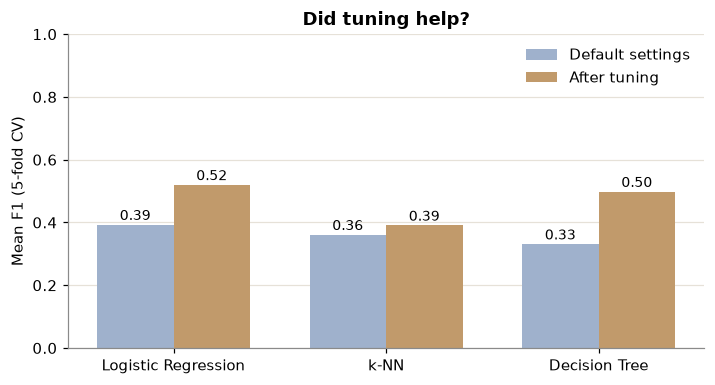

In [15]:
fig, ax = plt.subplots(figsize=(6.6, 3.6))
x = np.arange(len(names))
w = 0.36
before = [baseline_results.loc[n, "F1 mean"] for n in names]
after = [searches[n].best_score_ for n in names]
ax.bar(x - w/2, before, w, color=LIGHT_NAVY, label="Default settings")
ax.bar(x + w/2, after, w, color=CARAMEL, label="After tuning")
for i in range(len(names)):
    ax.text(x[i] - w/2, before[i] + 0.015, f"{before[i]:.2f}", ha="center", fontsize=9)
    ax.text(x[i] + w/2, after[i] + 0.015, f"{after[i]:.2f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1)
ax.set_ylabel("Mean F1 (5-fold CV)")
ax.set_title("Did tuning help?")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()


In [16]:
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Selected pipeline: {best_name}\n")
print(f"Test F1        : {f1_score(y_test, y_pred):.3f}")
print(f"Test precision : {precision_score(y_test, y_pred):.3f}")
print(f"Test recall    : {recall_score(y_test, y_pred):.3f}")
print(f"Test accuracy  : {accuracy_score(y_test, y_pred):.3f}")
print()
print(f"True negatives (TN)  = {tn}")
print(f"False positives (FP) = {fp}")
print(f"False negatives (FN) = {fn}")
print(f"True positives (TP)  = {tp}")
print()
print(classification_report(y_test, y_pred, target_names=["Not escalated", "Escalated"]))


Selected pipeline: Logistic Regression

Test F1        : 0.600
Test precision : 0.519
Test recall    : 0.711
Test accuracy  : 0.800

True negatives (TN)  = 117
False positives (FP) = 25
False negatives (FN) = 11
True positives (TP)  = 27

               precision    recall  f1-score   support

Not escalated       0.91      0.82      0.87       142
    Escalated       0.52      0.71      0.60        38

     accuracy                           0.80       180
    macro avg       0.72      0.77      0.73       180
 weighted avg       0.83      0.80      0.81       180



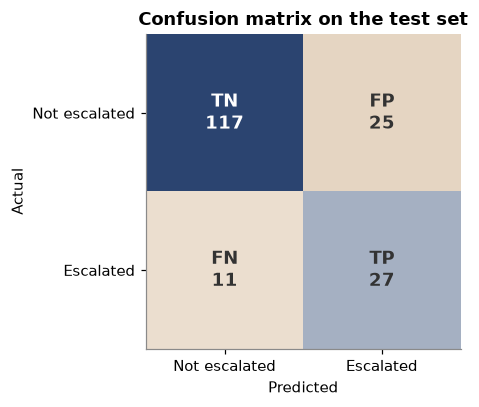

In [17]:
fig, ax = plt.subplots(figsize=(4.6, 3.8))
from matplotlib.colors import to_rgb
shade = np.zeros((2, 2, 3))
for i in range(2):
    for j in range(2):
        base = np.array(to_rgb(NAVY if i == j else CARAMEL))
        strength = 0.25 + 0.75 * cm[i, j] / cm.max()
        shade[i, j] = 1 - strength * (1 - base)
ax.imshow(shade)
labels = ["Not escalated", "Escalated"]
ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
tags = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        colour = "white" if (i == j and cm[i, j] > cm.max() * 0.6) else "#333333"
        ax.text(j, i, f"{tags[i][j]}\n{cm[i, j]}", ha="center", va="center",
                color=colour, fontsize=12, fontweight="bold")
ax.grid(False)
ax.set_title("Confusion matrix on the test set")
plt.tight_layout()
plt.show()


In [18]:
test_view = X_test.copy()
test_view["actual"] = y_test.values
test_view["predicted"] = y_pred
if hasattr(best_model.named_steps["model"], "predict_proba"):
    test_view["p_escalate"] = best_model.predict_proba(X_test)[:, 1].round(3)

groups = {
    "False positive (predicted 1, actual 0)": test_view[(test_view.predicted == 1) & (test_view.actual == 0)],
    "False negative (predicted 0, actual 1)": test_view[(test_view.predicted == 0) & (test_view.actual == 1)],
    "True positive": test_view[(test_view.predicted == 1) & (test_view.actual == 1)],
    "True negative": test_view[(test_view.predicted == 0) & (test_view.actual == 0)],
}
summary = pd.DataFrame({
    k: {
        "count": len(v),
        "avg complexity": v.complexity_score.mean(),
        "avg team experience": v.team_experience_years.mean(),
        "% High/Critical priority": v.priority.isin(["High", "Critical"]).mean() * 100,
    } for k, v in groups.items()
}).T.round(2)
print(summary)


                                        count  avg complexity  avg team experience  % High/Critical priority
False positive (predicted 1, actual 0)   25.0            7.72                 6.57                     60.00
False negative (predicted 0, actual 1)   11.0            5.10                 8.90                     45.45
True positive                            27.0            7.92                 4.26                     51.85
True negative                           117.0            4.25                 8.53                     24.79


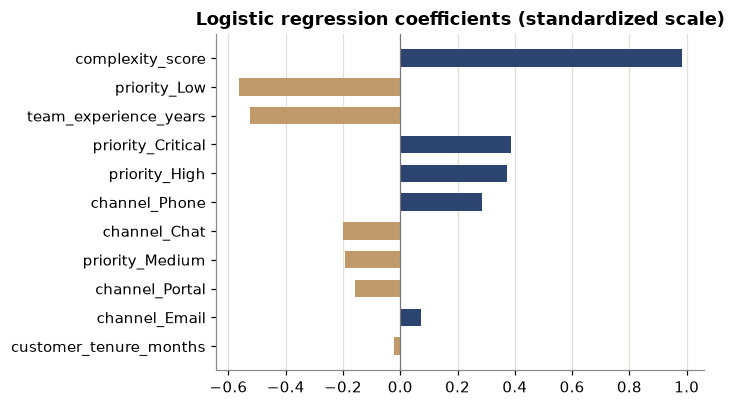

complexity_score          0.983
priority_Low             -0.565
team_experience_years    -0.524
priority_Critical         0.386
priority_High             0.372
channel_Phone             0.284
channel_Chat             -0.198
priority_Medium          -0.192
channel_Portal           -0.158
channel_Email             0.073
customer_tenure_months   -0.021
dtype: float64


In [19]:
prep_fitted = best_model.named_steps["prep"]
feat_names = [n.split("__", 1)[1] for n in prep_fitted.get_feature_names_out()]
fitted_model = best_model.named_steps["model"]
if hasattr(fitted_model, "coef_"):
    vals = fitted_model.coef_[0]
    title = "Logistic regression coefficients (standardized scale)"
elif hasattr(fitted_model, "feature_importances_"):
    vals = fitted_model.feature_importances_
    title = "Decision tree feature importances"
else:
    vals = None
if vals is not None:
    order = np.argsort(np.abs(vals))
    fig, ax = plt.subplots(figsize=(6.6, 3.8))
    colours = [NAVY if v >= 0 else CARAMEL for v in vals[order]]
    ax.barh(np.array(feat_names)[order], vals[order], color=colours, height=0.6)
    ax.axvline(0, color="#777777", lw=0.8)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()
    print(pd.Series(vals, index=feat_names).sort_values(key=np.abs, ascending=False).round(3))
